In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones normal y tope (semanas), coste normal (k€) y coste unitario de reducción (k€/semana) se adjunta. Además:

- los costes indirectos (oficina, alquileres, supervisión) son de 8 k€ por semana de duración;
- el contrato fija la entrega en la semana 22, con una penalización de 11 k€ por cada semana de retraso;
- y una prima de 6 k€ por cada semana de adelanto sobre ese plazo.

In [4]:
pregunta_1 = "1. Calcule la duración normal del proyecto y su coste total con esa duración (directo + indirecto + penalización o prima).  "
pregunta_2 = "2. Obtenga con Ackoff-Sasieni el sobrecoste directo acumulado de cada semana de reducción hasta la duración tope.  "
pregunta_3 = "3. Construya la tabla de coste total frente a duración, con las cuatro componentes, y determine la duración óptima. Dibuje las curvas.  "
pregunta_4 = "4. Analice la decisión paso a paso: ¿qué se compara en cada semana de reducción antes y después del plazo contractual? ¿A partir de qué prima por semana de adelanto convendría reducir una semana más que en el óptimo?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la duración normal del proyecto y su coste total con esa duración (directo + indirecto + penalización o prima).  

2. Obtenga con Ackoff-Sasieni el sobrecoste directo acumulado de cada semana de reducción hasta la duración tope.  

3. Construya la tabla de coste total frente a duración, con las cuatro componentes, y determine la duración óptima. Dibuje las curvas.  

4. Analice la decisión paso a paso: ¿qué se compara en cada semana de reducción antes y después del plazo contractual? ¿A partir de qué prima por semana de adelanto convendría reducir una semana más que en el óptimo?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, cost_normal, ucr   
    ('A'     , '---'      , 6       , 3           , 70         , 9     ),
    ('B'     , '---'      , 2       , 2           , 50         , np.inf),
    ('C'     , '---'      , 3       , 3           , 20         , np.inf),
    ('D'     , 'A,B,C'    , 2       , 2           , 20         , np.inf),
    ('E'     , 'D'        , 7       , 5           , 60         , 7     ),
    ('F'     , 'E'        , 5       , 5           , 60         , np.inf),
    ('G'     , 'F'        , 4       , 2           , 40         , 7     ),
    ('H'     , 'D'        , 4       , 2           , 70         , 2     ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'cost_normal', 'ucr']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,cost_normal,ucr
activity,,,,,
A,---,6,3,70,9.0
B,---,2,2,50,inf
C,---,3,3,20,inf
D,"A,B,C",2,2,20,inf
E,D,7,5,60,7.0
F,E,5,5,60,inf
G,F,4,2,40,7.0
H,D,4,2,70,2.0


El proyecto corresponde a la instalación de una planta fotovoltaica sobre cubierta; las actividades son las siguientes (las duraciones del cuadro están en días).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de sombras y producción',
    'B': 'Cálculo estructural de la cubierta',
    'C': 'Tramitación de permisos',
    'D': 'Acopio de módulos e inversores',
    'E': 'Montaje de la estructura soporte',
    'F': 'Colocación de módulos',
    'G': 'Cableado de corriente continua',
    'H': 'Instalación de inversores',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de sombras y producción
B,Cálculo estructural de la cubierta
C,Tramitación de permisos
D,Acopio de módulos e inversores
E,Montaje de la estructura soporte
F,Colocación de módulos
G,Cableado de corriente continua
H,Instalación de inversores


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
coste_indirecto_semanal, plazo_contrato, penalizacion_semanal, prima_semanal = 8, 22, 11, 6

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Calcule la duración normal del proyecto y su coste total con esa duración (directo + indirecto + penalización o prima).  

In [9]:
duracion_normal = proyecto.duration(datos_proyecto['duration'])
coste_directo_normal = float(datos_proyecto['cost_normal'].sum())
def coste_plazo(T):
    return penalizacion_semanal * max(0, T - plazo_contrato) - prima_semanal * max(0, plazo_contrato - T)
total_normal = coste_directo_normal + coste_indirecto_semanal * duracion_normal + coste_plazo(duracion_normal)
Markdown(f'''Duración normal {duracion_normal} semanas. Coste total = directo {coste_directo_normal:.0f} + indirecto {coste_indirecto_semanal}·{duracion_normal} = {coste_indirecto_semanal * duracion_normal} + penalización {penalizacion_semanal}·({duracion_normal} − {plazo_contrato}) = {coste_plazo(duracion_normal):.0f} → **{total_normal:.0f} k€**.''')

Duración normal 24 semanas. Coste total = directo 390 + indirecto 8·24 = 192 + penalización 11·(24 − 22) = 22 → **604 k€**.

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Obtenga con Ackoff-Sasieni el sobrecoste directo acumulado de cada semana de reducción hasta la duración tope.  

In [11]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni hasta la duración tope"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_tope, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=100, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,0,1,2,3,4,5,6,7
Route_1,9.0,,,inf,7.0,inf,7.0,,24.0,23.0,22.0,21.0,20.0,19.0,18.0,17.0
Route_2,9.0,,,inf,,,,2.0,12.0,12.0,12.0,12.0,12.0,11.0,10.0,9.0
Route_3,,inf,,inf,7.0,inf,7.0,,20.0,19.0,18.0,17.0,16.0,16.0,16.0,16.0
Route_4,,inf,,inf,,,,2.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0,8.0
Route_5,,,inf,inf,7.0,inf,7.0,,21.0,20.0,19.0,18.0,17.0,17.0,17.0,17.0
Route_6,,,inf,inf,,,,2.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0,9.0
0,3.0,0.0,0.0,0.0,2.0,0.0,2.0,2.0,,,,,,,,
1,3.0,0.0,0.0,0.0,1.0,0.0,2.0,2.0,,,,,,,,
2,3.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,,,,,,,,
3,3.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,,,,,,,,


In [12]:
#| tbl-cap: "Opciones consideradas en cada paso"
#| label: tbl-ackoffPaso
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr'], pasos)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,24,Route_1,E (7); G (7); A (9),E,7.0
2,23,Route_1,E (7); G (7); A (9),E,7.0
3,22,Route_1,G (7); A (9),G,7.0
4,21,Route_1,G (7); A (9),G,7.0
5,20,Route_1,A (9),A,9.0
6,19,Route_1,A (9),A,9.0
7,18,Route_1,A (9),A,9.0


In [13]:
resumen = pd.DataFrame({'actividades acortadas': [', '.join(acts) for acts in pasos.values()],
                        'sobrecoste del paso': [sum(datos_proyecto.loc[acts, 'ucr']) for acts in pasos.values()]},
                       index=pd.Index(range(1, len(pasos) + 1), name='paso'))
resumen['duración'] = duracion_normal - resumen.index
resumen['sobrecoste acumulado'] = resumen['sobrecoste del paso'].cumsum()
resumen

,actividades acortadas,sobrecoste del paso,duración,sobrecoste acumulado
paso,,,,
1,E,7.0,23,7.0
2,E,7.0,22,14.0
3,G,7.0,21,21.0
4,G,7.0,20,28.0
5,A,9.0,19,37.0
6,A,9.0,18,46.0
7,A,9.0,17,55.0


## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Construya la tabla de coste total frente a duración, con las cuatro componentes, y determine la duración óptima. Dibuje las curvas.  

In [15]:
#| tbl-cap: "Coste total según la duración"
#| label: tbl-costeTotal
curva = pd.DataFrame({'duración': [duracion_normal] + resumen['duración'].tolist(),
                      'coste directo': [coste_directo_normal] + (coste_directo_normal + resumen['sobrecoste acumulado']).tolist()}).set_index('duración')
curva['coste indirecto'] = coste_indirecto_semanal * curva.index
curva['penalización'] = [penalizacion_semanal * max(0, T - plazo_contrato) for T in curva.index]
curva['prima (negativa)'] = [-prima_semanal * max(0, plazo_contrato - T) for T in curva.index]
curva['coste total'] = curva.sum(axis=1)
curva

,coste directo,coste indirecto,penalización,prima (negativa),coste total
duración,,,,,
24,390.0,192,22,0,604.0
23,397.0,184,11,0,592.0
22,404.0,176,0,0,580.0
21,411.0,168,0,-6,573.0
20,418.0,160,0,-12,566.0
19,427.0,152,0,-18,561.0
18,436.0,144,0,-24,556.0
17,445.0,136,0,-30,551.0


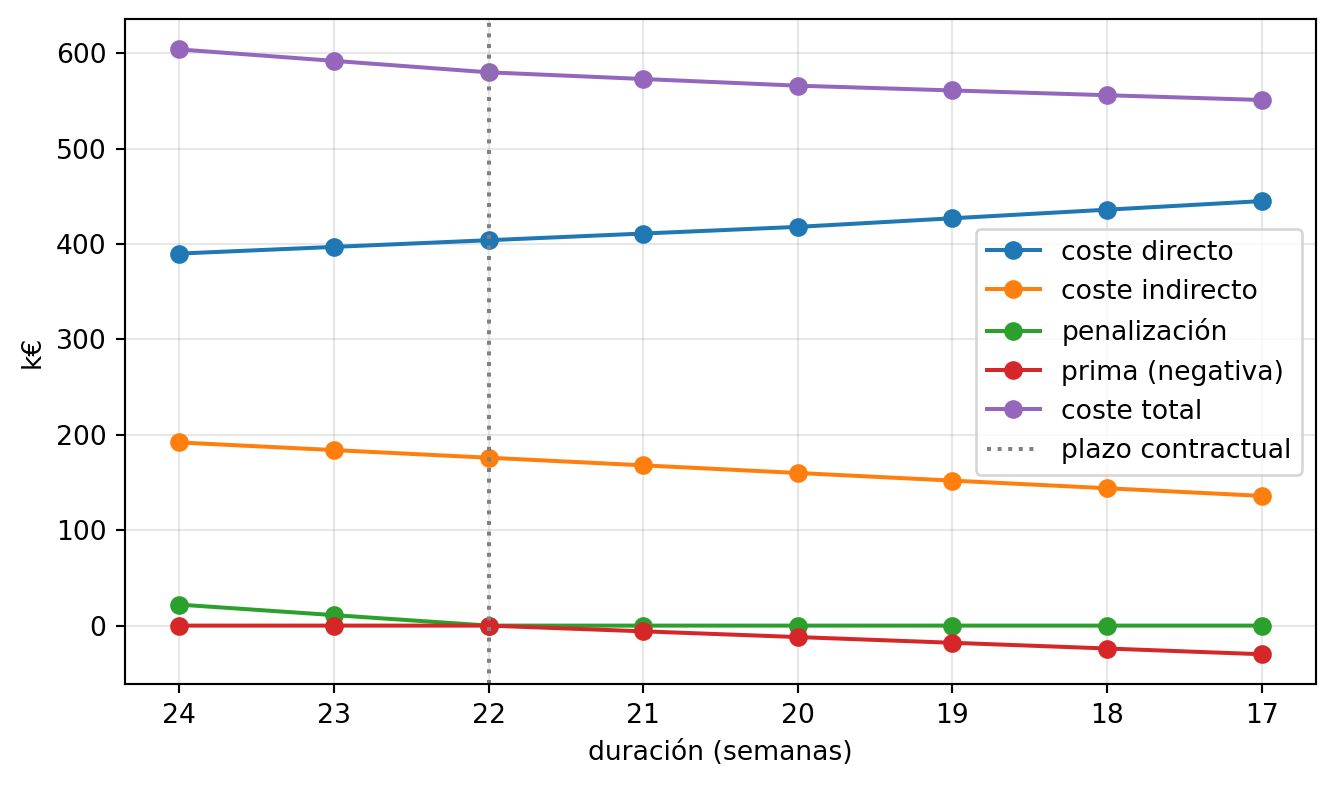

In [16]:
#| fig-cap: "Componentes del coste frente a la duración"
#| label: fig-curvas
ax = curva.plot(marker='o', figsize=(8, 4.5)); ax.axvline(plazo_contrato, color='grey', linestyle=':', label='plazo contractual')
ax.set_ylabel('k€'); ax.set_xlabel('duración (semanas)'); ax.invert_xaxis(); ax.legend(); ax.grid(alpha=0.3);

In [17]:
duracion_optima = int(curva['coste total'].idxmin())
Markdown(f'La duración óptima es {duracion_optima} semanas, con un coste total de {curva["coste total"].min():.0f} k€ (frente a {total_normal:.0f} sin reducir): {"antes del plazo" if duracion_optima < plazo_contrato else "en el plazo" if duracion_optima == plazo_contrato else "con retraso"}.')

La duración óptima es 17 semanas, con un coste total de 551 k€ (frente a 604 sin reducir): antes del plazo.

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Analice la decisión paso a paso: ¿qué se compara en cada semana de reducción antes y después del plazo contractual? ¿A partir de qué prima por semana de adelanto convendría reducir una semana más que en el óptimo?  

Cada semana de reducción cuesta el sobrecoste del paso de Ackoff-Sasieni y ahorra el coste indirecto semanal **más** la penalización semanal mientras el proyecto esté por detrás del plazo, o **más** la prima mientras esté por delante. La reducción compensa mientras el sobrecoste del paso sea menor que ese ahorro; como la penalización suele ser mayor que la prima, el ahorro marginal cae de golpe al cruzar el plazo y ahí suele detenerse la reducción.

In [19]:
decision = resumen[['sobrecoste del paso', 'duración']].copy()
decision['ahorro por la semana'] = [coste_indirecto_semanal + (penalizacion_semanal if T + 1 > plazo_contrato else prima_semanal) for T in decision['duración']]
decision['conviene'] = decision['sobrecoste del paso'] < decision['ahorro por la semana']
display(decision)
paso_siguiente = resumen[resumen['duración'] == duracion_optima - 1]
if len(paso_siguiente):
    sobre = float(paso_siguiente['sobrecoste del paso'].iloc[0])
    prima_necesaria = sobre - coste_indirecto_semanal
    display(Markdown(f'Reducir una semana más (a {duracion_optima - 1}) costaría {sobre:.0f} k€ y ahorraría {coste_indirecto_semanal} de indirectos más la prima: '
                     f'compensaría con una prima de más de {max(prima_necesaria, 0):.0f} k€/semana (ahora es {prima_semanal}).'))
else:
    display(Markdown('El óptimo ya está en la duración tope: ninguna prima permitiría reducir más.'))

,sobrecoste del paso,duración,ahorro por la semana,conviene
paso,,,,
1,7.0,23,19,True
2,7.0,22,19,True
3,7.0,21,14,True
4,7.0,20,14,True
5,9.0,19,14,True
6,9.0,18,14,True
7,9.0,17,14,True


El óptimo ya está en la duración tope: ninguna prima permitiría reducir más.